# Distribuição Gamma

## Exercício 1

Gere uma amostra de uma distribuição $\operatorname{Gamma}(k,\lambda)$, com $k$ inteiro, via soma de exponenciais. Verifique seu resultado comparando o histograma da sua distribuição com o de uma amostra gerada via NumPy.

## Exercício 2

Gere uma amostra de uma distribuição $\operatorname{Gamma}(\alpha,\lambda)$, com $\alpha>1$, via aceitação-rejeição. Verifique seu resultado comparando o histograma da sua distribuição com o de uma amostra gerada via NumPy.

## Exercício 3

Gere uma amostra de uma distribuição $\operatorname{Gamma}(\alpha,\lambda)$, com $\alpha>1$, utilizando a técnica vista em sala, isto é, usando o fato de que, se $G \sim \Gamma(\alpha+1,\lambda)$ e $U \sim \operatorname{Unif}(0,1)$ são independentes, então

$$
X = G U^{1/\alpha} \sim \Gamma(\alpha,\lambda).
$$
Verifique seu resultado comparando o histograma da sua distribuição com o de uma amostra gerada via NumPy.

# Distribuição Beta

## Exercício 4

Gere uma amostra de uma distribuição $\operatorname{Beta}(\alpha,\beta)$, com $\alpha,\beta>1$, via aceitação-rejeição. Verifique seu resultado comparando o histograma da sua distribuição com o de uma amostra gerada via NumPy.

## Exercício 5

Gere uma amostra de uma distribuição $\operatorname{Beta}(\alpha,\beta)$ utilizando o fato de que, se

$$
G_1 \sim \Gamma(\alpha,1), \qquad G_2 \sim \Gamma(\beta,1)
$$

são independentes, então

$$
X = \frac{G_1}{G_1+G_2} \sim \operatorname{Beta}(\alpha,\beta).
$$

Verifique seu resultado comparando o histograma da sua distribuição com o de uma amostra gerada via NumPy.


In [9]:
import numpy as np
import matplotlib.pyplot as plt
import math

(array([1.72097754e-02, 2.08564640e-01, 3.79709673e-01, 2.64876484e-01,
        1.06653985e-01, 2.91795897e-02, 6.19268125e-03, 1.00339680e-03,
        1.21623854e-04, 2.02706424e-05]),
 array([ 0.51853493,  1.50518349,  2.49183204,  3.47848059,  4.46512915,
         5.4517777 ,  6.43842626,  7.42507481,  8.41172336,  9.39837192,
        10.38502047]),
 <BarContainer object of 10 artists>)

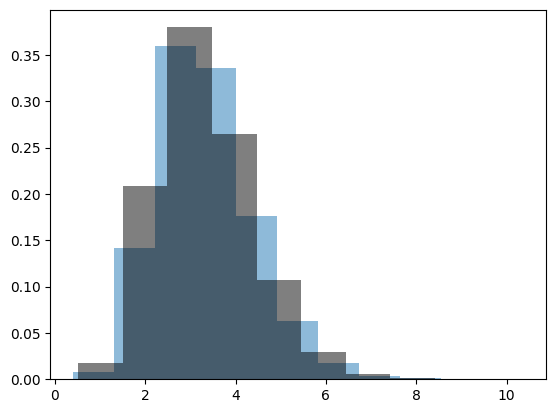

In [10]:
lamb = 3
tet = 1/lamb
k = 10
M = 100000
amostra_gamma = []
gamma = 0
for j in range(M):
  amostra_exp = []
  for i in range(k):
    lamb = 3
    u = np.random.uniform()
    exp = -np.log(u)/lamb
    amostra_exp.append(exp)
  amostra_gamma.append(np.sum(amostra_exp))

plt.hist(amostra_gamma, density=True, alpha = .5)
plt.hist(np.random.gamma(k, 1/lamb, size=M), density=True, alpha=.5, color = 'black')

(array([0.0324325 , 0.21016259, 0.37102778, 0.32173038, 0.20367609,
        0.10637859, 0.0402163 , 0.0077838 , 0.0012973 , 0.0025946 ]),
 array([0.83553246, 1.60636423, 2.377196  , 3.14802777, 3.91885954,
        4.68969131, 5.46052307, 6.23135484, 7.00218661, 7.77301838,
        8.54385015]),
 <BarContainer object of 10 artists>)

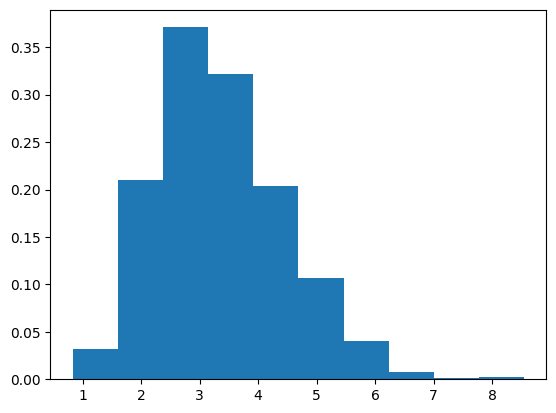

In [14]:
lamb = 3
tet = 1/lamb
N = 10
M = 1000
amostra_gamma = []
gamma = 0
for j in range(M):
  amostra_exp = []
  for i in range(N):
    lamb = 3
    u = np.random.uniform()
    exp = -np.log(u)/lamb
    amostra_exp.append(exp)

  amostra_gamma.append(np.sum(amostra_exp))

plt.hist(amostra_gamma, density=True)

## Exercício 2

Gere uma amostra de uma distribuição $\operatorname{Gamma}(\alpha,\lambda)$, com $\alpha>1$, via aceitação-rejeição. Verifique seu resultado comparando o histograma da sua distribuição com o de uma amostra gerada via NumPy.

In [15]:
def f(x, lamb, alpha):
  return (lamb**alpha)*np.exp(-x*lamb)*(x**(alpha-1))/math.gamma(alpha)

In [16]:
def g(x, mi):
  return np.exp(-mi*x)*mi

(array([1.50097679e-01, 5.27572626e-01, 4.90605894e-01, 2.68646164e-01,
        1.06120015e-01, 3.40986234e-02, 1.27471489e-02, 1.59339362e-03,
        1.43405425e-03, 4.78018085e-04]),
 array([0.16796304, 0.79555436, 1.42314568, 2.050737  , 2.67832831,
        3.30591963, 3.93351095, 4.56110227, 5.18869359, 5.81628491,
        6.44387622]),
 <BarContainer object of 10 artists>)

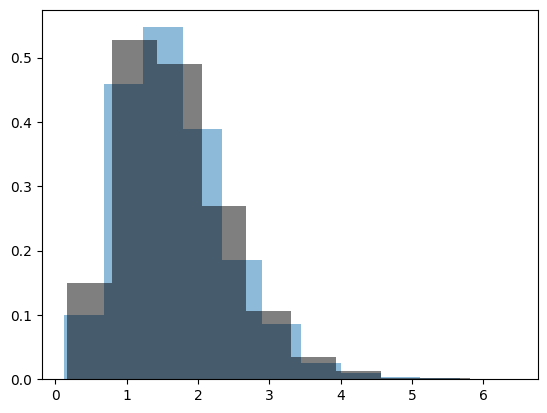

In [17]:
alpha = 5
lamb = 3
M = 10000
mi = lamb/alpha
amostra_exp = []
amostra = []



c = (lamb**alpha)*(((alpha-1)/(lamb-mi))**(alpha-1))*np.exp(-(alpha-1))/(math.gamma(alpha)*mi)

for i in range(M):
  u = np.random.uniform()
  y = -np.log(u)/mi
  U = np.random.uniform()
  while U*c*g(y, mi) > f(y, lamb, alpha):
    u = np.random.uniform()
    y = -np.log(u)/mi
    U = np.random.uniform()
  amostra.append(y)

plt.hist(amostra, density=True, alpha = .5)
plt.hist(np.random.gamma(alpha, 1/lamb, size=M), density=True, alpha=.5, color = 'black')

## Exercício 3

Gere uma amostra de uma distribuição $\operatorname{Gamma}(\alpha,\lambda)$, com $\alpha>1$, utilizando a técnica vista em sala, isto é, usando o fato de que, se $G \sim \Gamma(\alpha+1,\lambda)$ e $U \sim \operatorname{Unif}(0,1)$ são independentes, então

$$
X = G U^{1/\alpha} \sim \Gamma(\alpha,\lambda).
$$
Verifique seu resultado comparando o histograma da sua distribuição com o de uma amostra gerada via NumPy.


In [36]:
def gamma_ar(alpha, lamb, M):

  mi = lamb/alpha


  amostra = []
  c = (lamb**alpha)*(((alpha-1)/(lamb-mi))**(alpha-1))*np.exp(-(alpha-1))/(math.gamma(alpha)*mi)
  for i in range(M):
    u = np.random.uniform()
    y = -np.log(u)/mi
    U = np.random.uniform()
    while U*c*g(y, mi) > f(y, lamb, alpha):
      u = np.random.uniform()
      y = -np.log(u)/mi
      U = np.random.uniform()
    amostra.append(y)
  return amostra

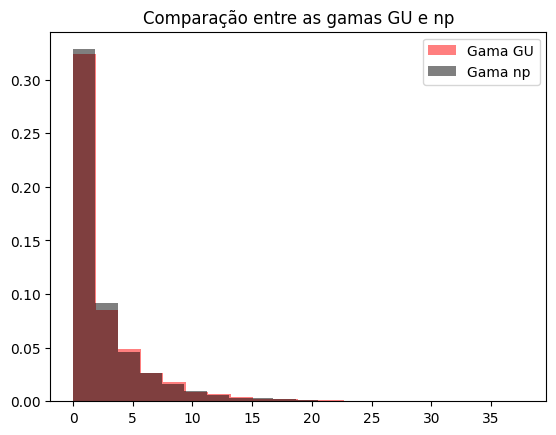

In [51]:
alpha = 0.5
beta = 5
teta = 2
M = 10000
G = gamma_ar(alpha+1, 1/beta, 10000)
u = np.random.uniform(size=10000)**(1/alpha)
amostrap = G * u
plt.hist(amostrap, bins =20, color='red', alpha=.5, density=True, label = 'Gama GU')
plt.hist(np.random.gamma(alpha, beta, size=M), density=True, bins=20, color='black', alpha=.5, label ='Gama np')
plt.title('Comparação entre as gamas GU e np')
plt.legend()
plt.show()

# Distribuição Beta

## Exercício 4

Gere uma amostra de uma distribuição $\operatorname{Beta}(\alpha,\beta)$, com $\alpha,\beta>1$, via aceitação-rejeição. Verifique seu resultado comparando o histograma da sua distribuição com o de uma amostra gerada via NumPy.

## Exercício 5

Gere uma amostra de uma distribuição $\operatorname{Beta}(\alpha,\beta)$ utilizando o fato de que, se

$$
G_1 \sim \Gamma(\alpha,1), \qquad G_2 \sim \Gamma(\beta,1)
$$

são independentes, então

$$
X = \frac{G_1}{G_1+G_2} \sim \operatorname{Beta}(\alpha,\beta).
$$

Verifique seu resultado comparando o histograma da sua distribuição com o de uma amostra gerada via NumPy.


In [68]:
def f_beta(x):
  return math.gamma(alpha + beta)/(math.gamma(alpha)*math.gamma(beta)) * x**(alpha-1) * (1-x)**(beta-1)

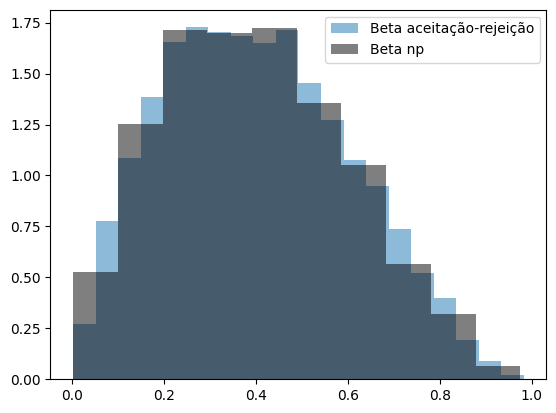

In [73]:
amostra = []
M = 10000
alpha = 2
beta = 3
ye = (alpha-1)/(alpha + beta - 2)
c = (ye**(alpha-1))*(1-ye)**(beta-1)*math.gamma(alpha + beta)/ (math.gamma(alpha)*math.gamma(beta))
for i in range(M):
  y = np.random.uniform()
  u = np.random.uniform()
  while u*c > f_beta(y):
   y = np.random.uniform()
   u = np.random.uniform()
  amostra.append(y)

plt.hist(amostra, bins=20, density=True, alpha=.5, label='Beta aceitação-rejeição')
plt.hist(np.random.beta(alpha, beta, M), density=True, alpha=.5, label='Beta np', color='black')
plt.legend()

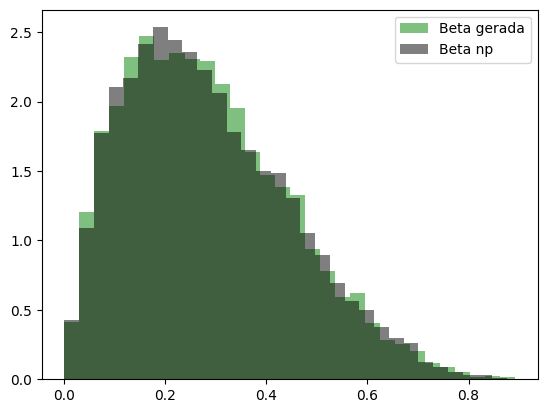

In [85]:
alha = 4
beta = 5
M = 10000
amostra = []
g1 = np.array(gamma_ar(alpha, 1, M))
g2 = np.array(gamma_ar(beta, 1, M))
amostra = g1/(g1+g2)
plt.hist(amostra, density=True, color = 'green', label='Beta gerada', bins=30, alpha=.5)
plt.hist(np.random.beta(alpha, beta, M), color = 'black', label='Beta np', bins=30, alpha=.5, density=True)
plt.legend()